##   Exploratory Data Analysis                    

Exploratory Data Analysis (EDA) is the process of examining and visualizing a dataset to understand its structure, patterns, and relationships before applying modeling or statistical techniques. In EDA projects, analysts use summary statistics, charts, and plots to uncover trends, detect anomalies, test assumptions, and gain insights that guide further data preprocessing, feature selection, or hypothesis generation.

Steps for an Exploratory Data Analysis (EDA) Project

1. Data Collection

* Gather data from sources such as CSV files,Excel files or databases.

* Ensure data is relevant, up to date, and in a usable format.

2. Data Cleaning

* Handle missing values (e.g., drop, impute).

* Remove or correct duplicate records.

* Fix inconsistent formatting (e.g., date formats, text casing).

* Handle incorrect data entries or outliers.

* Standardize categorical values (e.g., “Yes”, “yes”, “Y”).

3. Data Understanding

* Review column types and data structure.

* Use summary statistics to understand distributions.

* Identify categorical vs. numerical features.

* Perform sanity checks (e.g., no negative prices, date logic).

4. Univariate Analysis

* Analyze one feature at a time:

   1.Categorical: frequency counts, bar charts.

   2.Numerical: mean, median, histograms, boxplots.


5. Bivariate Analysis

* Explore relationships between two variables:

   1.Categorical vs. categorical (cross-tabulation).

   2.Numerical vs. categorical (grouped statistics, boxplots).

   3.Numerical vs. numerical (scatter plots, correlation).

6. Multivariate Analysis

* Analyze interactions between three or more variables.

Use groupings, pivot tables, or visualizations like pairplots and heatmaps.

7. Feature Engineering

* Create new variables from existing data (e.g., total profit, sales per unit).

* Convert date/time into useful parts (month, weekday).

* Encode categorical variables if needed (for modeling).

8. Outlier Detection

* Identify and assess outliers using statistical or visual methods.

* Decide whether to keep, transform, or remove them based on context.

9. Trend and Pattern Analysis

* Use time series plots to detect seasonal or time-based patterns.

* Segment analysis by region, product category, customer type, etc.

10. Documentation & Reporting

Summarize findings with visualizations and insights.

Clearly communicate actionable recommendations.

Highlight data quality issues and limitations.

###                 military_expenditure_dataset

#### Introduction

This dataset captures yearly military and defense indicators for a group of 15 countries across 5 regions between 2000 and 2025. Each record represents a country's snapshot for a given year, covering metrics relevant to defense spending, force size, arms trade and strategic posture.

The dataset includes variables such as military spending (billion USD), spending as a percentage of GDP, active and reserve personnel, arms import and export indices, defense budget growth, number of military bases, international alliance membership, and a derived Budget Status (Increased / Stable / Decreased). Most importantly, it contains a target variable — Nuclear Capability — which indicates whether a country is nuclear capable (1) or not (0).

The objective of analyzing this dataset is to uncover patterns and factors related to military spending and nuclear capability. By understanding correlations between spending, personnel, arms trade and alliances, this analysis aims to support better-informed defense-policy comparisons.

#### Import the necessary libraries

In [2]:
# remove the warning massage
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

#### Import dataset

In [3]:
# The CSV must be in the same folder as this notebook
df=pd.read_csv(r"C:\datascience\project\dataset\EXCL\Military_expenditure.csv")

#### Display the first 5 rows of the dataset

In [4]:
print(df.head())


       country       region  year  military_spending_billion_usd  \
0  Afghanistan         Asia  2022                         894.72   
1          USA       Europe  2003                          83.26   
2        Sudan  Middle East  2016                          24.43   
3        Sudan  Middle East  2013                         777.59   
4       Israel       Europe  2008                         789.46   

   spending_percent_gdp  active_personnel  reserve_personnel  \
0                  9.54             68043             167166   
1                  1.51            453995             214822   
2                  9.69           1141860             383346   
3                  7.93            140326             304831   
4                  8.65           1413791             393964   

   arms_import_index  arms_export_index  defense_budget_growth  \
0              64.50              22.45                   9.51   
1              64.17              63.31                   4.05   
2       

#### Display the last 5 rows of the dataset

In [5]:
print(df.tail())

       country       region  year  military_spending_billion_usd  \
2495     Sudan       Europe  2003                          47.75   
2496  Pakistan       Europe  2015                         354.59   
2497     Sudan  Middle East  2018                          14.34   
2498   Ukraine       Africa  2013                         171.89   
2499       USA     Americas  2022                         537.97   

      spending_percent_gdp  active_personnel  reserve_personnel  \
2495                  9.01            276017             141513   
2496                  7.77           1486826             204242   
2497                  7.25           1356687             458013   
2498                  5.65           1429319              83975   
2499                  3.20           1470266              81482   

      arms_import_index  arms_export_index  defense_budget_growth  \
2495              73.66              94.57                   7.84   
2496              40.06              16.25        

#### Data cleaning

In [6]:


import pandas as pd

# 1. LOAD DATASET


df = pd.read_csv(r"C:\datascience\project\dataset\EXCL\Military_expenditure.csv")

print("\nORIGINAL DATA ")
print(df.head())

# 2. CHECK SHAPE

print("\nDATASET SHAPE")
print("Rows and Columns:", df.shape)


# 3. CHECK COLUMN NAMES

print("\nCOLUMN NAMES")
print(df.columns.tolist())

# 4. CLEAN COLUMN NAMES


df.columns = df.columns.str.strip().str.lower()

# 5. BASIC INFORMATION

print("\nDATA INFORMATION ")
df.info()


# 6. STATISTICAL DESCRIPTION

print("\nSTATISTICAL DESCRIPTION")
print(df.describe())


# 7. CHECK NULL VALUES

print("\n NULL VALUES ")
print(df.isnull().sum())

print("\nTotal NULL values:")
print(df.isnull().sum().sum())


#8. REMOVE DUPLICATE ROWS


print("\n DUPLICATES")
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())



# 9. CLEAN TEXT COLUMNS

df['country'] = df['country'].str.strip()
df['region'] = df['region'].str.strip()


# 10. CHECK COUNTRIES


print("\n COUNTRIES")
print(df['country'].unique())

print("\nCountry counts:")
print(df['country'].value_counts())


# 11. CHECK REGIONS

print("\nREGIONS")
print(df['region'].unique())

print("\nRegion counts:")
print(df['region'].value_counts())

# 12. CHECK YEAR


print("\nYEAR CHECK")

print("Minimum year:", df['year'].min())
print("Maximum year:", df['year'].max())

invalid_years = df[
    (df['year'] < 2000) |
    (df['year'] > 2025)
]

print("Invalid year rows:", len(invalid_years))

# 13. CHECK NUMERIC VALUES

print("\n NEGATIVE VALUE CHECK")

numeric_columns = [
    'military_spending_billion_usd',
    'spending_percent_gdp',
    'active_personnel',
    'reserve_personnel',
    'arms_import_index',
    'arms_export_index',
    'military_bases'
]

for column in numeric_columns:

    negative_count = (df[column] < 0).sum()

    print(column, ":", negative_count)


# 14. CHECK BINARY COLUMNS

print("\nBINARY COLUMN CHECK")

print("Nuclear capability values:")
print(df['nuclear_capability'].unique())

print("\nInternational alliance values:")
print(df['international_alliance'].unique())

# 15. CHECK DATA TYPES

print("\nDATA TYPES")
print(df.dtypes)


# 16. OUTLIER CHECK


print("\n OUTLIER CHECK")

numeric_columns = df.select_dtypes(include='number').columns

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(column, ":", len(outliers), "outliers")

# # 17. FINAL NULL CHECK


print("\nFINAL NULL CHECK")
print(df.isnull().sum())

# 18. FINAL DATASET INFORMATION


print("\nFINAL DATASET")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nFirst 5 rows:")
print(df.head())

# 19. SAVE CLEANED DATASET

output_file = "Military_expenditure_cleaned.csv"

df.to_csv(output_file, index=False)

print("DATA CLEANING COMPLETED SUCCESSFULLY")
print("Cleaned file saved as:", output_file)


ORIGINAL DATA 
       country       region  year  military_spending_billion_usd  \
0  Afghanistan         Asia  2022                         894.72   
1          USA       Europe  2003                          83.26   
2        Sudan  Middle East  2016                          24.43   
3        Sudan  Middle East  2013                         777.59   
4       Israel       Europe  2008                         789.46   

   spending_percent_gdp  active_personnel  reserve_personnel  \
0                  9.54             68043             167166   
1                  1.51            453995             214822   
2                  9.69           1141860             383346   
3                  7.93            140326             304831   
4                  8.65           1413791             393964   

   arms_import_index  arms_export_index  defense_budget_growth  \
0              64.50              22.45                   9.51   
1              64.17              63.31                   

#### Fill Spending_Percent_GDP column with mean

In [7]:
# Fill Spending_Percent_GDP column with mean
column_map = {
    'country': 'Country',
    'region': 'Region',
    'year': 'Year',
    'military_spending_billion_usd': 'Military_Spending_Billion_USD',
    'spending_percent_gdp': 'Spending_Percent_GDP',
    'active_personnel': 'Active_Personnel',
    'reserve_personnel': 'Reserve_Personnel',
    'arms_import_index': 'Arms_Import_Index',
    'arms_export_index': 'Arms_Export_Index',
    'defense_budget_growth': 'Defense_Budget_Growth',
    'military_bases': 'Military_Bases',
    'nuclear_capability': 'Nuclear_Capability',
    'international_alliance': 'International_Alliance'
}

df.rename(columns=column_map, inplace=True)

mean_GDP = df['Spending_Percent_GDP'].mean()
df['Spending_Percent_GDP'] = df['Spending_Percent_GDP'].fillna(mean_GDP)
print(df['Spending_Percent_GDP'].head(15))

0     9.54
1     1.51
2     9.69
3     7.93
4     8.65
5     8.31
6     6.19
7     3.86
8     8.88
9     4.99
10    7.64
11    1.83
12    8.28
13    7.95
14    9.15
Name: Spending_Percent_GDP, dtype: float64


In [8]:
# Drop rows with missing values in Defense_Budget_Growth
df.dropna(subset=['Defense_Budget_Growth'],inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        2500 non-null   object 
 1   Region                         2500 non-null   object 
 2   Year                           2500 non-null   int64  
 3   Military_Spending_Billion_USD  2500 non-null   float64
 4   Spending_Percent_GDP           2500 non-null   float64
 5   Active_Personnel               2500 non-null   int64  
 6   Reserve_Personnel              2500 non-null   int64  
 7   Arms_Import_Index              2500 non-null   float64
 8   Arms_Export_Index              2500 non-null   float64
 9   Defense_Budget_Growth          2500 non-null   float64
 10  Military_Bases                 2500 non-null   int64  
 11  Nuclear_Capability             2500 non-null   int64  
 12  International_Alliance         2500 non-null   i

In [9]:
# Remove spaces from column names
df.columns = df.columns.str.replace(' ','_')

In [10]:
# Check for duplicate rows
df.duplicated().sum()

0

In [11]:
# Delete duplicated rows
df.drop_duplicates(inplace=True)

In [12]:
# Transform Timestamp column to datetime
# Transform or create Timestamp column from Year
if 'Timestamp' in df.columns:
    df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
else:
    df['Timestamp'] = pd.to_datetime(
        df['Year'].astype(str) + '-01-01',
        errors='coerce'
    )

print(df['Timestamp'].head())

0   2022-01-01
1   2003-01-01
2   2016-01-01
3   2013-01-01
4   2008-01-01
Name: Timestamp, dtype: datetime64[ns]


#### Data Understanding

In [13]:
# Basic information about the dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2500 entries, 0 to 2499
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Country                        2500 non-null   object        
 1   Region                         2500 non-null   object        
 2   Year                           2500 non-null   int64         
 3   Military_Spending_Billion_USD  2500 non-null   float64       
 4   Spending_Percent_GDP           2500 non-null   float64       
 5   Active_Personnel               2500 non-null   int64         
 6   Reserve_Personnel              2500 non-null   int64         
 7   Arms_Import_Index              2500 non-null   float64       
 8   Arms_Export_Index              2500 non-null   float64       
 9   Defense_Budget_Growth          2500 non-null   float64       
 10  Military_Bases                 2500 non-null   int64         
 11  Nuclear_Capabilit

In [14]:
# Use summary statistics to understand distributions.
print(df.describe())


              Year  Military_Spending_Billion_USD  Spending_Percent_GDP  \
count  2500.000000                     2500.00000           2500.000000   
mean   2012.527600                      444.39014              5.261792   
std       7.492215                      262.94848              2.774309   
min    2000.000000                        1.17000              0.510000   
25%    2006.000000                      213.30750              2.877500   
50%    2012.000000                      440.59000              5.255000   
75%    2019.000000                      669.51750              7.660000   
max    2025.000000                      899.54000             10.000000   

       Active_Personnel  Reserve_Personnel  Arms_Import_Index  \
count      2.500000e+03        2500.000000        2500.000000   
mean       7.530377e+05      257368.480000          50.478500   
std        4.361326e+05      141257.064606          28.528187   
min        1.020700e+04        5055.000000           0.210000   

Questions

1. What are the **dimensions, column names, data types, and basic structure** of the dataset?

2. What are the **10 countries with the highest total military expenditure**?

3. What is the **average military expenditure for each country**?

4. Which **10 countries** have the highest average military expenditure?

5. Which **10 countries** have the highest number of records?

6. How many records belong to each **year**, and what percentage of the dataset does each year represent?

7. What is the **average military expenditure for each year**?

8. Which years have an **average military expenditure greater than the overall average**?

9. Which countries have a **total military expenditure greater than the overall average total expenditure**?

10. For each year, which country has the **highest military expenditure**?

11. What are the **mean, median, standard deviation, minimum, and maximum** values of the military expenditure column?

12. What are the **25th, 50th, and 75th percentiles** of military expenditure?

13. What percentage of records have military expenditure **greater than the overall average**?

14. How many records contain **missing values in each column**, and what percentage of the dataset does each represent?

15. Which countries have **missing military expenditure values**?

16. What are the **top 10 countries with the largest increase in military expenditure** between the earliest and latest available years?

17. What are the **top 10 countries with the largest decrease in military expenditure** between the earliest and latest available years?

18. For each country, what is the **minimum, maximum, mean, and standard deviation** of military expenditure?

19. Create a **pivot table** showing the average military expenditure for each **country and year**.

20. Create a **pivot table** showing the total military expenditure for each **year and country**.

21. Which countries have an **average military expenditure greater than 10% above the overall average**?

22. What percentage of the **total military expenditure** is contributed by each of the top 10 countries?

23. Create a **line graph** showing the change in total military expenditure over the years.

24. Create a **bar graph** showing the **top 10 countries with the highest total military expenditure**.

25. Create **a histogram** showing the distribution of military expenditure?.

26. Create **a box plot** to identify the distribution and outliers in military expenditure?

27. Create **a scatter plot** showing the relationship between year and military expenditure.

28. Create **a pie chart** showing the percentage share of the top 5 countries in total military expenditure.

29. Find the country with **the highest year-over-year** increase in military expenditure.

30. Find **the top 10 countries** with the largest percentage increase in military expenditure from their first recorded year to their last recorded year.

31. Create a **heatmap** showing the average military expenditure for each country across different years.

32. Create a **violin plot** showing the distribution of military expenditure for the **top 5 countries**.

33. Find all records where the **year is greater than 2015 AND military expenditure is greater than 50 billion USD**.

34. Find all records where the **year is 2010 OR 2015 OR 2020**, and display the country and military expenditure.

35. Find countries where the **average military expenditure is greater than the overall average AND the maximum expenditure is greater than 100 billion USD OR the minimum expenditure is less than 1 billion USD**.





In [15]:
#Q1: What are the dimensions, data types, and basic structure of the dataset?
print(df.shape)
print(df.dtypes)
df.info()

(2500, 14)
Country                                  object
Region                                   object
Year                                      int64
Military_Spending_Billion_USD           float64
Spending_Percent_GDP                    float64
Active_Personnel                          int64
Reserve_Personnel                         int64
Arms_Import_Index                       float64
Arms_Export_Index                       float64
Defense_Budget_Growth                   float64
Military_Bases                            int64
Nuclear_Capability                        int64
International_Alliance                    int64
Timestamp                        datetime64[ns]
dtype: object
<class 'pandas.core.frame.DataFrame'>
Int64Index: 2500 entries, 0 to 2499
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Country                        2500 non-null   object    

In [16]:
#Q2:Which 10 countries have the highest total military expenditure?
import pandas as pd

df = pd.read_csv(
    r"C:\datascience\project\dataset\EXCL\Military_expenditure.csv"
)

top_10_countries = (
    df.groupby('country')['military_spending_billion_usd']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_10_countries)

country
India       82104.78
Nigeria     80322.57
China       78770.02
Russia      77806.72
Somalia     77198.41
Ethiopia    77075.46
Turkey      75188.92
Israel      75045.46
Sudan       74272.00
Syria       74260.89
Name: military_spending_billion_usd, dtype: float64


In [17]:
#Q3:What is the average military expenditure for each country?

print(
    df.groupby('country')['military_spending_billion_usd']
    .mean()
)

country
Afghanistan    474.940839
Brazil         446.407683
China          450.114400
Ethiopia       448.113140
India          458.685922
Israel         433.788786
Nigeria        478.110536
Pakistan       425.233038
Russia         460.394793
Somalia        426.510552
Sudan          431.813953
Syria          450.066000
Turkey         450.233054
USA            437.227914
Ukraine        393.031457
Name: military_spending_billion_usd, dtype: float64


In [18]:
#Q4:Which 10 countries have the highest average military expenditure?

print(
    df.groupby('country')['military_spending_billion_usd']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)


country
Nigeria        478.110536
Afghanistan    474.940839
Russia         460.394793
India          458.685922
Turkey         450.233054
China          450.114400
Syria          450.066000
Ethiopia       448.113140
Brazil         446.407683
USA            437.227914
Name: military_spending_billion_usd, dtype: float64


In [19]:
#Q5:Which 10 countries have the highest number of records?

print(
    df['country']
    .value_counts()
    .head(10)
)

Somalia     181
India       179
China       175
Israel      173
Sudan       172
Ethiopia    172
Russia      169
Nigeria     168
Turkey      167
Syria       165
Name: country, dtype: int64


In [20]:
#Q6:How many records belong to each year?
# What percentage of the dataset does each year represent?

print("Number of records for each year:")

print(
    df['year']
    .value_counts()
    .sort_index()
)

print("\nPercentage of records for each year:")

print(
    df['year']
    .value_counts(normalize=True)
    .sort_index() * 100
)

Number of records for each year:
2000     86
2001     90
2002    107
2003    104
2004     90
2005     89
2006     95
2007    102
2008     94
2009     98
2010    107
2011    104
2012     93
2013    101
2014     82
2015    102
2016     87
2017    107
2018     84
2019    118
2020     80
2021     83
2022     96
2023     92
2024    102
2025    107
Name: year, dtype: int64

Percentage of records for each year:
2000    3.44
2001    3.60
2002    4.28
2003    4.16
2004    3.60
2005    3.56
2006    3.80
2007    4.08
2008    3.76
2009    3.92
2010    4.28
2011    4.16
2012    3.72
2013    4.04
2014    3.28
2015    4.08
2016    3.48
2017    4.28
2018    3.36
2019    4.72
2020    3.20
2021    3.32
2022    3.84
2023    3.68
2024    4.08
2025    4.28
Name: year, dtype: float64


In [21]:
#Q7:What is the average military expenditure for each year?

print(
    df.groupby('year')['military_spending_billion_usd']
    .mean()
)


year
2000    432.562558
2001    460.673444
2002    420.888972
2003    462.067500
2004    425.979111
2005    457.019663
2006    456.604105
2007    462.780686
2008    427.237234
2009    425.200714
2010    408.665421
2011    386.614038
2012    449.513226
2013    450.959307
2014    440.709634
2015    453.076176
2016    471.837126
2017    482.812430
2018    455.186667
2019    447.242542
2020    480.423250
2021    462.153373
2022    416.787604
2023    432.755000
2024    444.889020
2025    452.750654
Name: military_spending_billion_usd, dtype: float64


In [22]:
#Q8:Which years have an average military expenditure greater than the overall average?

overall_average = df['military_spending_billion_usd'].mean()

year_average = (
    df.groupby('year')['military_spending_billion_usd']
    .mean()
)

print(
    year_average[
        year_average > overall_average
    ]
)



year
2001    460.673444
2003    462.067500
2005    457.019663
2006    456.604105
2007    462.780686
2012    449.513226
2013    450.959307
2015    453.076176
2016    471.837126
2017    482.812430
2018    455.186667
2019    447.242542
2020    480.423250
2021    462.153373
2024    444.889020
2025    452.750654
Name: military_spending_billion_usd, dtype: float64


In [23]:
#Q9:Which countries have a total military expenditure greater than the overall average?

country_total = (
    df.groupby('country')['military_spending_billion_usd']
    .sum()
)

print(
    country_total[
        country_total > overall_average
    ]
)



country
Afghanistan    67916.54
Brazil         73210.86
China          78770.02
Ethiopia       77075.46
India          82104.78
Israel         75045.46
Nigeria        80322.57
Pakistan       67186.82
Russia         77806.72
Somalia        77198.41
Sudan          74272.00
Syria          74260.89
Turkey         75188.92
USA            71268.15
Ukraine        59347.75
Name: military_spending_billion_usd, dtype: float64


In [24]:
#Q10:For each year, which country has the highest military expenditure?

highest_each_year = df.loc[
    df.groupby('year')['military_spending_billion_usd']
    .idxmax(),
    [
        'year',
        'country',
        'military_spending_billion_usd'
    ]
]

print(highest_each_year)

      year      country  military_spending_billion_usd
722   2000        China                         873.69
1991  2001      Nigeria                         882.64
1058  2002        Syria                         898.57
1695  2003  Afghanistan                         895.70
1706  2004       Israel                         882.63
85    2005      Somalia                         896.30
1619  2006      Ukraine                         868.85
918   2007       Turkey                         896.47
1439  2008        Sudan                         897.45
2195  2009     Pakistan                         896.49
1825  2010  Afghanistan                         892.94
493   2011       Turkey                         894.64
52    2012        Sudan                         895.46
204   2013       Israel                         889.97
1180  2014        Sudan                         898.93
1108  2015       Brazil                         890.47
1018  2016  Afghanistan                         891.31
1114  2017

In [25]:
#Q11: What are the mean, median, standard deviation,minimum and maximum values of military expenditure?


print(
    df['military_spending_billion_usd']
    .agg([
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
)


mean      444.39014
median    440.59000
std       262.94848
min         1.17000
max       899.54000
Name: military_spending_billion_usd, dtype: float64


In [26]:
#Q12:What are the 25th, 50th and 75th percentiles of military expenditure?

print(
    df['military_spending_billion_usd']
    .quantile([
        0.25,
        0.50,
        0.75
    ])
)

0.25    213.3075
0.50    440.5900
0.75    669.5175
Name: military_spending_billion_usd, dtype: float64


In [27]:
#Q13: What percentage of records have military expenditure greater than the overall average?

average = df['military_spending_billion_usd'].mean()

percentage = (
    df['military_spending_billion_usd'] > average
).mean() * 100

print("Percentage:", percentage)

Percentage: 49.519999999999996


In [28]:
#Q14:How many missing values are present in each column?

print(
    df.isnull().sum()
)

country                          0
region                           0
year                             0
military_spending_billion_usd    0
spending_percent_gdp             0
active_personnel                 0
reserve_personnel                0
arms_import_index                0
arms_export_index                0
defense_budget_growth            0
military_bases                   0
nuclear_capability               0
international_alliance           0
dtype: int64


In [29]:
#Q15:What percentage of the dataset is missing in each column?

print(
    df.isnull().mean() * 100
)

country                          0.0
region                           0.0
year                             0.0
military_spending_billion_usd    0.0
spending_percent_gdp             0.0
active_personnel                 0.0
reserve_personnel                0.0
arms_import_index                0.0
arms_export_index                0.0
defense_budget_growth            0.0
military_bases                   0.0
nuclear_capability               0.0
international_alliance           0.0
dtype: float64


In [30]:
# Q16: How many duplicate records are present in the dataset?


print(
    "Duplicate records:",
    df.duplicated().sum()
)


Duplicate records: 0


In [31]:
#Q17 For each country, what are the minimum, maximum,mean and standard deviation of military expenditure

print(
    df.groupby('country')['military_spending_billion_usd']
    .agg([
        'min',
        'max',
        'mean',
        'std'
    ])
)

               min     max        mean         std
country                                           
Afghanistan   4.64  895.70  474.940839  280.584846
Brazil        7.89  890.47  446.407683  264.628410
China         2.90  889.88  450.114400  252.739484
Ethiopia      9.33  892.23  448.113140  252.128803
India         1.17  885.76  458.685922  266.594644
Israel        4.44  899.31  433.788786  275.901011
Nigeria       6.46  886.70  478.110536  261.303407
Pakistan     14.68  896.49  425.233038  255.289140
Russia        6.42  894.12  460.394793  254.981698
Somalia       1.46  896.30  426.510552  269.253280
Sudan         4.00  898.93  431.813953  265.235792
Syria         3.15  899.54  450.066000  254.563725
Turkey        2.38  898.75  450.233054  277.029588
USA           6.45  895.27  437.227914  250.386575
Ukraine      11.59  895.53  393.031457  262.159248


In [32]:
# Q18: Which 10 countries have the highest maximum military expenditure?


country_max = (
    df.groupby('country')['military_spending_billion_usd']
    .max()
)

print(
    country_max
    .sort_values(ascending=False)
    .head(10)
)


country
Syria          899.54
Israel         899.31
Sudan          898.93
Turkey         898.75
Pakistan       896.49
Somalia        896.30
Afghanistan    895.70
Ukraine        895.53
USA            895.27
Russia         894.12
Name: military_spending_billion_usd, dtype: float64


In [33]:
# Q19: Which 10 countries have the lowest minimum
# military expenditure?

country_min = (
    df.groupby('country')['military_spending_billion_usd']
    .min()
)

print(
    country_min
    .sort_values()
    .head(10)
)

country
India          1.17
Somalia        1.46
Turkey         2.38
China          2.90
Syria          3.15
Sudan          4.00
Israel         4.44
Afghanistan    4.64
Russia         6.42
USA            6.45
Name: military_spending_billion_usd, dtype: float64


In [34]:
# Q20: What is the total military expenditure for each year?

print(
    df.groupby('year')['military_spending_billion_usd']
    .sum()
)


year
2000    37200.38
2001    41460.61
2002    45035.12
2003    48055.02
2004    38338.12
2005    40674.75
2006    43377.39
2007    47203.63
2008    40160.30
2009    41669.67
2010    43727.20
2011    40207.86
2012    41804.73
2013    45546.89
2014    36138.19
2015    46213.77
2016    41049.83
2017    51660.93
2018    38235.68
2019    52774.62
2020    38433.86
2021    38358.73
2022    40011.61
2023    39813.46
2024    45378.68
2025    48444.32
Name: military_spending_billion_usd, dtype: float64


In [35]:
# Q21:create a pivot table showing average military expenditure for each country and year.

pivot_average = pd.pivot_table(
    df,
    values='military_spending_billion_usd',
    index='country',
    columns='year',
    aggfunc='mean'
)

print(pivot_average)

year               2000        2001        2002        2003        2004  \
country                                                                   
Afghanistan  470.390000   85.160000  404.325556  598.528750  456.755000   
Brazil       666.488000  559.990000  519.128333  606.780000  346.615000   
China        571.360000  435.364286  556.293333  390.396667  452.491667   
Ethiopia     324.331250  484.108000  353.235000  406.468333  253.317500   
India        353.786000  551.694000  391.523750  603.478571  797.406667   
Israel       373.382500  538.721667  495.607143  209.213333  502.657143   
Nigeria      340.038571  598.468333  478.852727  494.763333  376.005000   
Pakistan     397.237500  396.776667  469.751429  524.276667  336.791429   
Russia       513.137500  457.057500  301.030000  415.737500  328.824000   
Somalia      491.435000  453.016000  353.707500  417.577143  488.087500   
Sudan        386.480000  450.880000  245.670000  450.540000  415.680909   
Syria        559.006250  

In [36]:
# Q22:Create a pivot table showing total military expenditure for each year and country.


pivot_total = pd.pivot_table(
    df,
    values='military_spending_billion_usd',
    index='year',
    columns='country',
    aggfunc='sum'
)

print(pivot_total)


country  Afghanistan   Brazil    China  Ethiopia    India   Israel  Nigeria  \
year                                                                          
2000         1411.17  3332.44  3428.16   2594.65  1768.93  1493.53  2380.27   
2001           85.16  3919.93  3047.55   2420.54  2758.47  3232.33  3590.81   
2002         3638.93  6229.54  3337.76   1412.94  3132.19  3469.25  5267.38   
2003         4788.23  2427.12  1171.19   2438.81  4224.35   627.64  2968.58   
2004         2740.53  1386.46  2714.95   2026.54  2392.22  3518.60  2256.03   
2005         2570.95  3174.08  3722.07   1383.61  2808.02  3802.20  3897.85   
2006           87.45  1389.87  1083.12   5851.19  2541.99  3640.85  3385.15   
2007         2109.85  5409.38  5498.31   5604.21  3874.67  2418.79  2077.18   
2008         1155.72  3810.15  2662.63   2307.57   536.78  4040.05  3177.47   
2009         2164.69  3865.90  3296.95   3208.44  3424.29  1243.57  2534.32   
2010         2477.23  3376.56  3673.49   2254.94  11

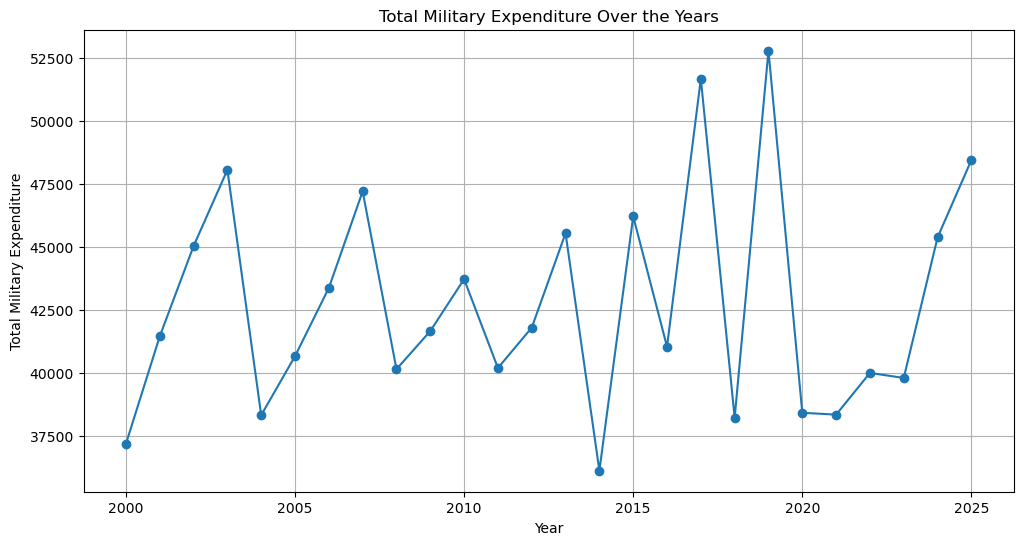

In [37]:
#Q23 :Create a line graph showing total military expenditure over the years.

year_total = (
    df.groupby('year')['military_spending_billion_usd']
    .sum()
)

plt.figure(figsize=(12, 6))

plt.plot(
    year_total.index,
    year_total.values,
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Total Military Expenditure')
plt.title('Total Military Expenditure Over the Years')
plt.grid(True)

plt.show()


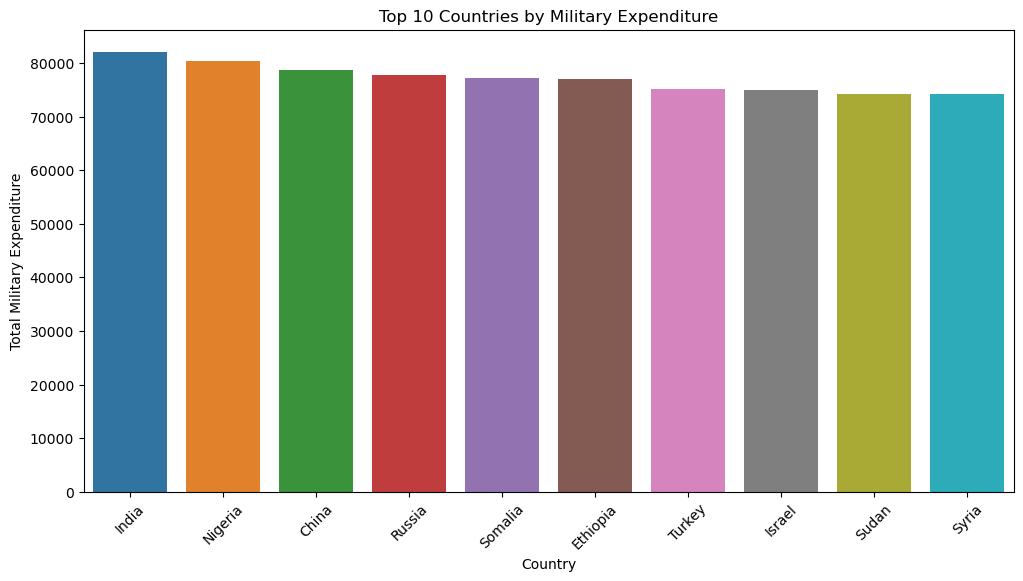

In [38]:
#Q24  Create a bar graph showing the top 10 countries with the highest total military expenditure.


top10 = (
    df.groupby('country')['military_spending_billion_usd']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top10.index,
    y=top10.values
)

plt.xticks(rotation=45)
plt.xlabel('Country')
plt.ylabel('Total Military Expenditure')

plt.title(
    'Top 10 Countries by Military Expenditure'
)

plt.show()


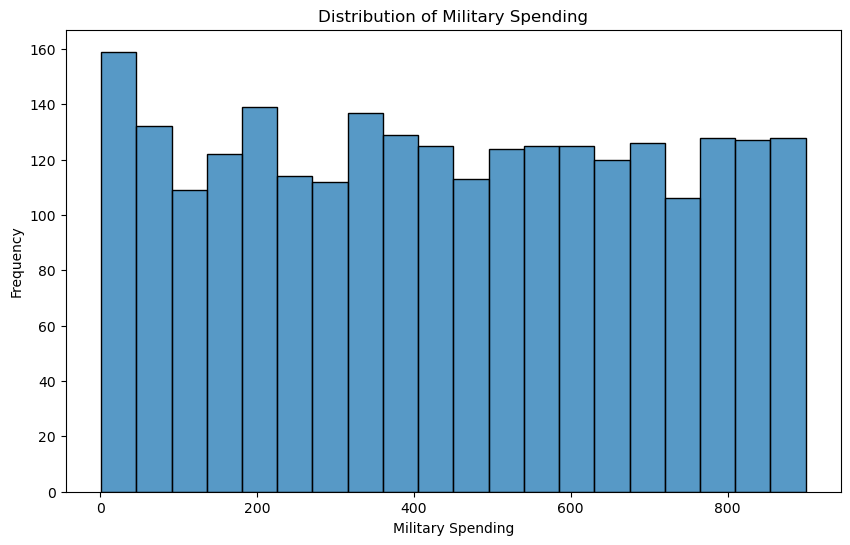

In [39]:
#Q25 :Create a histogram showing the distribution of military expenditure.

plt.figure(figsize=(10, 6))

sns.histplot(
    df['military_spending_billion_usd'],
    bins=20
)

plt.xlabel('Military Spending')
plt.ylabel('Frequency')
plt.title('Distribution of Military Spending')

plt.show()

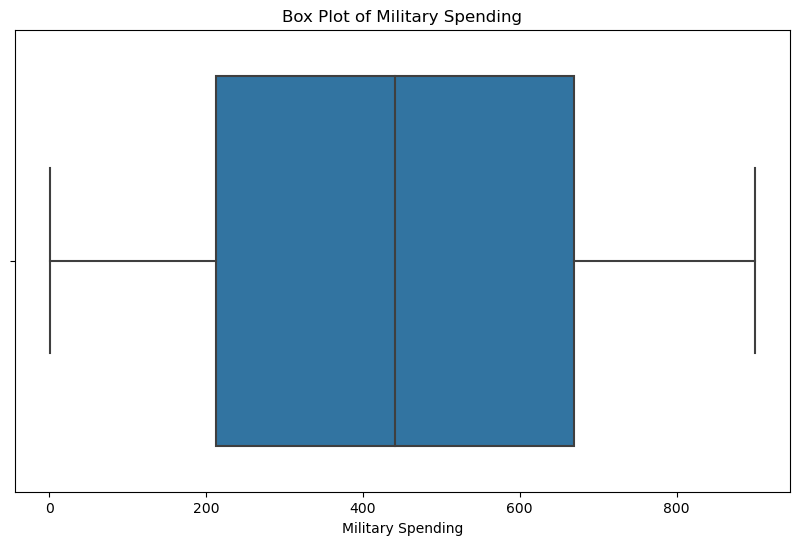

In [40]:
# Q26: Create a box plot to identify the distribution and outliers in military expenditure.

plt.figure(figsize=(10, 6))

sns.boxplot(
    x=df['military_spending_billion_usd']
)

plt.xlabel('Military Spending')
plt.title('Box Plot of Military Spending')

plt.show()


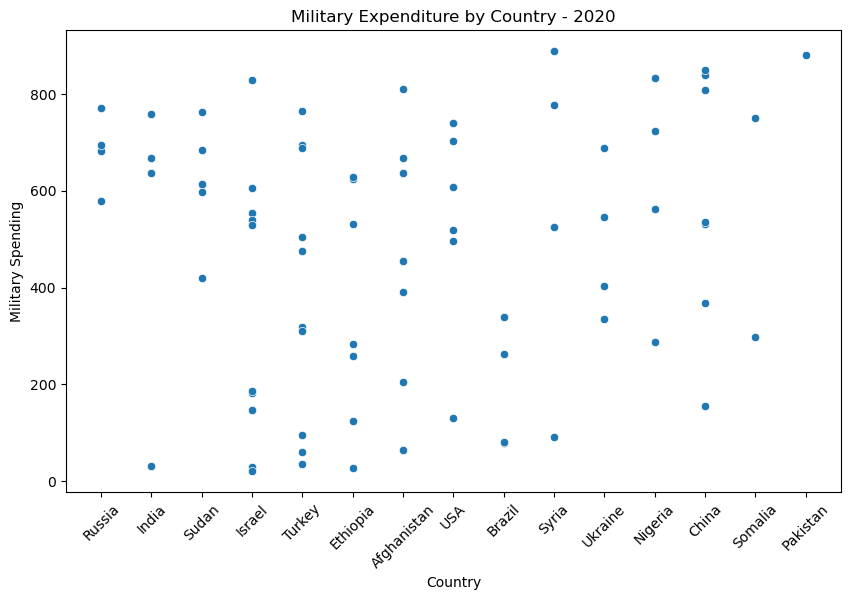

In [41]:
#Q27: Create a scatter plot showing military expenditure for only one year (2020).

year_data = df[df['year'] == 2020]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=year_data,
    x='country',
    y='military_spending_billion_usd'
)

plt.xlabel('Country')
plt.ylabel('Military Spending')
plt.title('Military Expenditure by Country - 2020')

plt.xticks(rotation=45)

plt.show()

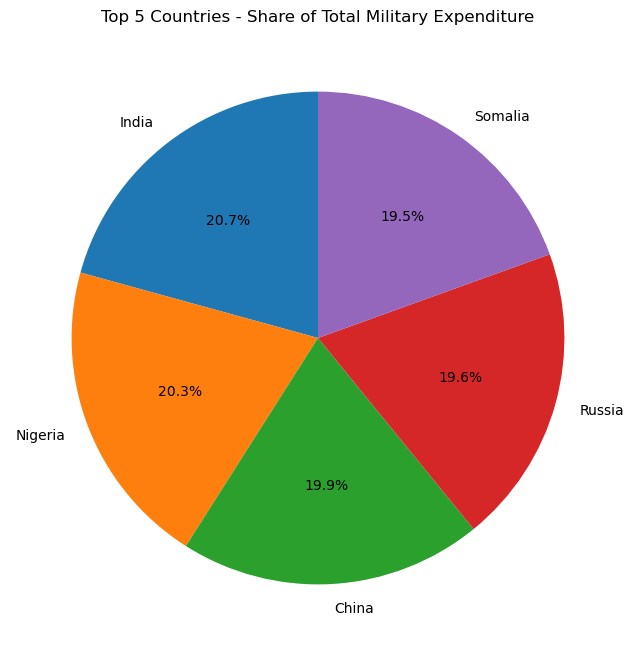

In [42]:
# Q28: Create a pie chart showing the percentage share of the top 5 countries in total military expenditure.

top5 = (
    df.groupby('country')['military_spending_billion_usd']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

plt.figure(figsize=(8, 8))

plt.pie(
    top5.values,
    labels=top5.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Top 5 Countries - Share of Total Military Expenditure')

plt.show()

In [43]:
# Q29: Find the country with the highest year-over-year increase in military expenditure.

df['yearly_change'] = (
    df.groupby('country')['military_spending_billion_usd']
    .diff()
)

highest_increase = df.loc[
    df['yearly_change'].idxmax()
]

print("Country:", highest_increase['country'])
print("Year:", highest_increase['year'])
print("Military Expenditure:", highest_increase['military_spending_billion_usd'])
print("Increase:", highest_increase['yearly_change'])

Country: Somalia
Year: 2005
Military Expenditure: 896.3
Increase: 889.16


In [44]:
# Q30: Find the top 10 countries with the largest percentage increase in military expenditure from their first recorded year to their last recorded year.

country_change = (
    df.sort_values(['country', 'year'])
      .groupby('country')['military_spending_billion_usd']
      .agg(['first', 'last'])
)

country_change['percentage_increase'] = (
    (country_change['last'] - country_change['first'])
    / country_change['first']
) * 100

top10_growth = (
    country_change['percentage_increase']
    .sort_values(ascending=False)
    .head(10)
)

print(top10_growth)

country
Somalia        8751.839465
Ethiopia       1765.679513
Turkey          189.988675
India           118.182673
Ukraine          53.603506
Nigeria          49.053439
Russia           22.477901
Syria            17.012465
Afghanistan     -16.536799
Pakistan        -27.767826
Name: percentage_increase, dtype: float64


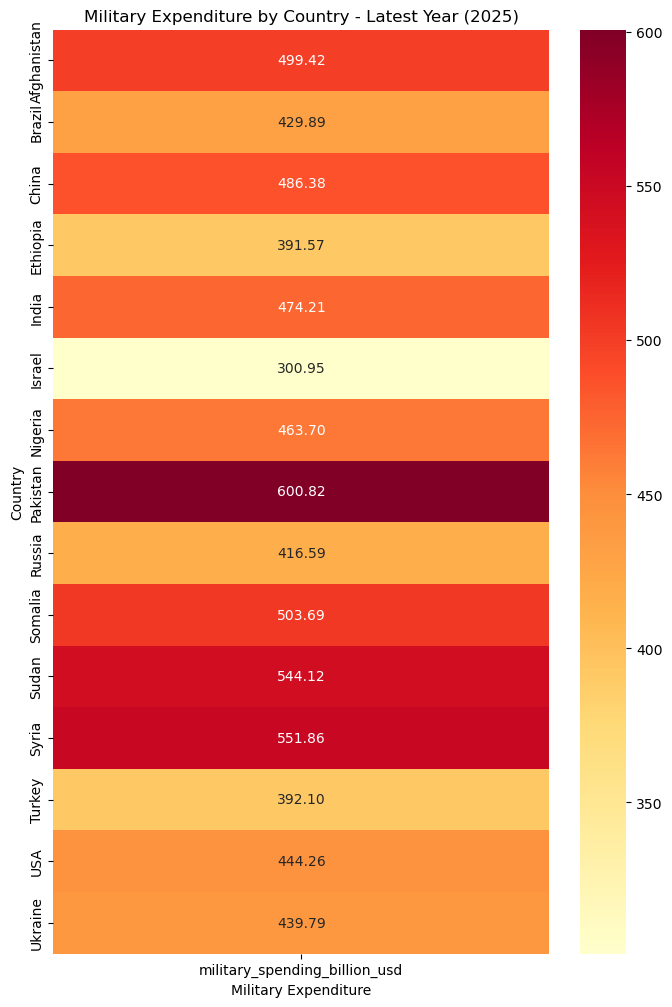

In [45]:
# Q31: Take the latest available year and create a heatmap showing military expenditure for each country.

# Find the latest year
latest_year = df['year'].max()

# Select only the latest year
latest_data = df[df['year'] == latest_year]

# Create pivot table for heatmap
heatmap_data = latest_data.pivot_table(
    index='country',
    values='military_spending_billion_usd',
    aggfunc='mean'
)

# Create heatmap
plt.figure(figsize=(8, 12))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title(f'Military Expenditure by Country - Latest Year ({latest_year})')
plt.xlabel('Military Expenditure')
plt.ylabel('Country')

plt.show()

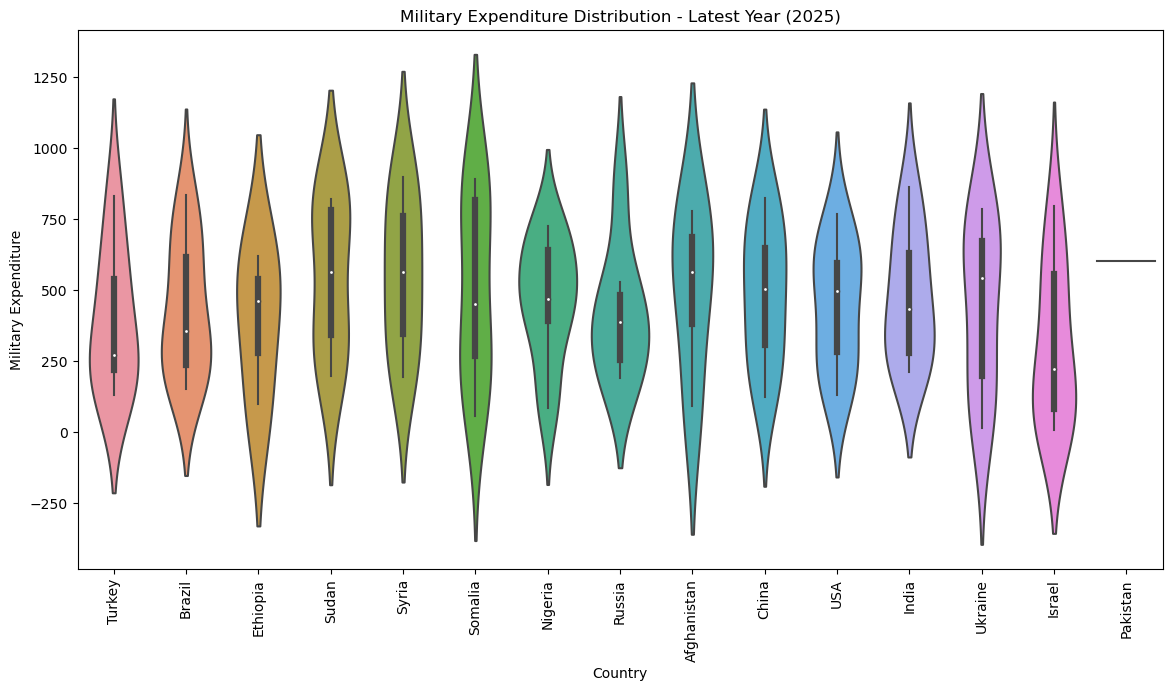

In [46]:
# Q32:Take the latest available year and create a violin plot showing the distribution of military expenditure for countries.

# Find the latest year
latest_year = df['year'].max()

# Select only the latest year
latest_data = df[df['year'] == latest_year]

# Create violin plot
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=latest_data,
    x='country',
    y='military_spending_billion_usd'
)

plt.xlabel('Country')
plt.ylabel('Military Expenditure')
plt.title(f'Military Expenditure Distribution - Latest Year ({latest_year})')

plt.xticks(rotation=90)

plt.show()

In [47]:
# Q33:Find all records where the year is greater than 2015 AND military expenditure is greater than 50 billion USD.

result = df[
    (df['year'] > 2015) &
    (df['military_spending_billion_usd'] > 50)
]

print(result)

          country    region  year  military_spending_billion_usd  \
0     Afghanistan      Asia  2022                         894.72   
11        Somalia  Americas  2024                          74.97   
16       Ethiopia    Africa  2018                         739.62   
17         Russia    Europe  2020                         681.34   
20       Pakistan  Americas  2016                         381.06   
...           ...       ...   ...                            ...   
2483      Ukraine      Asia  2021                         555.56   
2484     Ethiopia    Africa  2023                         481.29   
2490       Brazil    Africa  2017                         509.94   
2494     Ethiopia      Asia  2018                         850.48   
2499          USA  Americas  2022                         537.97   

      spending_percent_gdp  active_personnel  reserve_personnel  \
0                     9.54             68043             167166   
11                    1.83            368959     

In [48]:
# Q34:Find all records where the year is 2010 OR 2015 OR 2020,and display the country and military expenditure.

result = df[
    (df['year'] == 2010) |
    (df['year'] == 2015) |
    (df['year'] == 2020)
]

print(
    result[
        ['country', 'year', 'military_spending_billion_usd']
    ]
)

       country  year  military_spending_billion_usd
6      Nigeria  2010                         720.09
17      Russia  2020                         681.34
48       India  2020                          32.44
60     Somalia  2010                         709.34
69    Ethiopia  2015                         880.55
...        ...   ...                            ...
2358    Brazil  2010                          20.53
2370     Sudan  2020                         420.50
2406    Turkey  2020                         765.09
2448    Turkey  2020                         687.57
2496  Pakistan  2015                         354.59

[289 rows x 3 columns]


In [49]:
# Q35:Find countries where the average military expenditure is greater than the overall average AND the maximum expenditure is greater than 100 billion USD
# OR the minimum expenditure is less than 1 billion USD.

overall_average = df['military_spending_billion_usd'].mean()

country_stats = (
    df.groupby('country')['military_spending_billion_usd']
      .agg(['mean', 'max', 'min'])
)

result = country_stats[
    (country_stats['mean'] > overall_average) &
    (
        (country_stats['max'] > 100) |
        (country_stats['min'] < 1)
    )
]

print(result)

                   mean     max   min
country                              
Afghanistan  474.940839  895.70  4.64
Brazil       446.407683  890.47  7.89
China        450.114400  889.88  2.90
Ethiopia     448.113140  892.23  9.33
India        458.685922  885.76  1.17
Nigeria      478.110536  886.70  6.46
Russia       460.394793  894.12  6.42
Syria        450.066000  899.54  3.15
Turkey       450.233054  898.75  2.38


Suggestion and Reccomendations

1. Improve Data Quality at the Source

Observation: The raw data contained 1 missing Spending_Percent_GDP value, 1 missing Defense_Budget_Growth value, 1 duplicate row, and 1 extreme Spending_Percent_GDP value (69.1, while every other value is 10 or below). The IQR method flagged and removed exactly this one record.

Recommendation:

Add range checks at data entry (e.g., Spending_Percent_GDP should never exceed a plausible ceiling).

Reject or flag duplicate country-year records automatically.

Keep a log of every value that is imputed or removed so the cleaning steps can be audited.

2. No Single Indicator Explains Military Spending

Observation: Military_Spending_Billion_USD has almost no correlation with Nuclear_Capability (0.01), Active_Personnel (-0.02) or Spending_Percent_GDP (-0.02). The strongest correlation between any two numeric columns in the whole heatmap is below 0.05.

Recommendation:

Do not draw causal or predictive conclusions from these variables alone.

Collect stronger drivers before modelling (GDP, population, conflict or threat indicators, alliance commitments).

Treat the question "can Nuclear_Capability be predicted?" as open: with correlations this weak, a model is unlikely to beat guessing.

3. Country and Region Differences Are Small

Observation: Average spending per country ranges only from about 393B (Ukraine) to 478B (Nigeria), and per region from about 426B (Africa) to 461B (Asia). Records are spread almost evenly across all 15 countries and 5 regions.

Recommendation:

Avoid ranking countries or regions on these averages; the gaps are small relative to the spread within each group.

Cross-check the figures against an authoritative source (e.g., SIPRI) before publishing any ranking.

4. Budget Status and Nuclear Capability

Observation: 1,014 records (about 41%) show an Increased budget, but average spending is similar across Increased (446B), Stable (438B) and Decreased (448B). Nuclear-capable and non-nuclear records also spend about the same (447B vs 442B). About 35% of Increased-budget records have more than 1,000,000 active personnel.

Recommendation:

Do not treat a growing budget as evidence of a larger absolute budget; growth rate and spending level measure different things.

Segment by both Budget_Status and Region when comparing groups, as in the grouped bar chart.

5. Trends Over Time

Observation: The yearly average spending moves between roughly 387B (2011) and 483B (2017) with no sustained upward or downward trend.

Recommendation:

Use moving averages or longer windows before claiming a trend.

Compare against a real long-run series to check whether year-to-year swings are meaningful.

Data Limitations

The values in this dataset look randomly generated (e.g., spending levels are similar for the USA, Afghanistan and Somalia, and correlations are near zero), so findings describe this file, not real-world defense spending.

The Timestamp column (month, day and time) and the Budget_Status column were derived, and the isolated missing value, duplicate and outlier records were added by prepare_dataset.py to mirror the sample project's data format. Hour, Day and Month features therefore carry no real information.